# Speech Emotion Router (SER): Baseline Modeling & Benchmark Validation

In the previous phase ([`01_signal_eda_features.ipynb`](./01_signal_eda_features.ipynb)), acoustic audits and cross-speaker MFCC comparisons established that physical anatomy and pitch baseline disparities justify a two-stage hierarchical model (Stage 1: Gender $\rightarrow$ Stage 2: Emotion). 

However, before implementing that phased pipeline, we must empirically put that hypothesis to the test. This phase sets our benchmark performance floor by evaluating two initial baselines against a composite target variable (`gender_emotion`), framing the task as a flat 16-class multi-classification problem (e.g., `M_angry`, `F_fearful`, `M_neutral`).

**Baseline Scope & Experimental Design:**
- **Zero-Rule Benchmark (Dummy Classifier):** Establish the absolute mathematical lower bound using uniform and stratified dummy strategies to gauge random chance across 16 imbalanced classes.
- **Linear Benchmark (Monolithic Logistic Regression):** Fit a flat Multinomial Logistic Regression pipeline with `StandardScaler` to test whether the 26 MFCC summary statistics ($\mu, \sigma$) are linearly separable across joint demographic and affective targets.
- **Strict Leakage Prevention:** Evaluate all baselines strictly via `StratifiedGroupKFold` ($k=5$) grouped by `actor_id`, ensuring no speaker's vocal tract anatomy appears in both training and test folds.
- **Hypothesis Diagnostics:** Assess macro $F_1$-score, class-level precision/recall, and a $16 \times 16$ normalized confusion matrix to pinpoint where a single flat model fails—specifically measuring whether errors stem from true emotional ambiguity or cross-gender acoustic interference.

In [206]:
# Standard library
from pathlib import Path
import pprint
from typing import Any, cast

# Data handling and numerical arrays
import joblib
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
from matplotlib.container import BarContainer
import seaborn as sns

# Scikit-learn: pipelines and preprocessing
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Scikit-learn: validation and evaluation metrics
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_predict,
    cross_validate,
)

# Scikit-learn: estimators
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Plotting style configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 100

In [207]:
# Define paths and import the processed feature dataset
project_root = Path.cwd().resolve().parent
data_processed_path = project_root / "data" / "processed"

In [208]:
SEED = 24

## Loading & Preparing the Data

In [209]:
df = pd.read_parquet(data_processed_path / "ser_features.parquet")

# Verify loaded shape and integrity
print(f"Loaded shape: {df.shape}")  # Expect (1440, 32)
df.info()

Loaded shape: (1440, 32)
<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 32 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   file_path     1440 non-null   str    
 1   actor_id      1440 non-null   int64  
 2   gender        1440 non-null   str    
 3   emotion       1440 non-null   str    
 4   intensity     1440 non-null   str    
 5   repetition    1440 non-null   int64  
 6   mfcc_mean_0   1440 non-null   float64
 7   mfcc_std_0    1440 non-null   float64
 8   mfcc_mean_1   1440 non-null   float64
 9   mfcc_std_1    1440 non-null   float64
 10  mfcc_mean_2   1440 non-null   float64
 11  mfcc_std_2    1440 non-null   float64
 12  mfcc_mean_3   1440 non-null   float64
 13  mfcc_std_3    1440 non-null   float64
 14  mfcc_mean_4   1440 non-null   float64
 15  mfcc_std_4    1440 non-null   float64
 16  mfcc_mean_5   1440 non-null   float64
 17  mfcc_std_5    1440 non-null   float64
 18  mfcc_mean_6   

In [210]:
# Construct the composite target label for monolithic classification
df["gender_emotion"] = df["gender"] + "_" + df["emotion"]
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 33 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   file_path       1440 non-null   str    
 1   actor_id        1440 non-null   int64  
 2   gender          1440 non-null   str    
 3   emotion         1440 non-null   str    
 4   intensity       1440 non-null   str    
 5   repetition      1440 non-null   int64  
 6   mfcc_mean_0     1440 non-null   float64
 7   mfcc_std_0      1440 non-null   float64
 8   mfcc_mean_1     1440 non-null   float64
 9   mfcc_std_1      1440 non-null   float64
 10  mfcc_mean_2     1440 non-null   float64
 11  mfcc_std_2      1440 non-null   float64
 12  mfcc_mean_3     1440 non-null   float64
 13  mfcc_std_3      1440 non-null   float64
 14  mfcc_mean_4     1440 non-null   float64
 15  mfcc_std_4      1440 non-null   float64
 16  mfcc_mean_5     1440 non-null   float64
 17  mfcc_std_5      1440 non-null   float64
 18 

In [211]:
# Validate - Inspect class counts and normalized distributions
target_counts = pd.DataFrame({
    "count": df["gender_emotion"].value_counts(),
    "proportion": df["gender_emotion"].value_counts(normalize=True).round(4)
})

display(target_counts)
print(f"Total classes: {df['gender_emotion'].nunique()}")

,count,proportion
gender_emotion,,
M_disgust,96,0.0667
F_angry,96,0.0667
M_fearful,96,0.0667
F_disgust,96,0.0667
M_angry,96,0.0667
M_calm,96,0.0667
F_calm,96,0.0667
M_sad,96,0.0667
F_sad,96,0.0667


Total classes: 16


This is as expected - there are 48 `normal` for all emotions and 48 `strong` for all emotions except `neutral`.

We can now drop some of the old features:
- `file_path`, `repetition`, `intensity` - metadata columns, no value for modeling 
- `gender`, `emotion` - these are now superseded by the new target variable


In [212]:
cols_to_drop = ["file_path", "gender", "intensity", "emotion", "repetition"]
df = df.drop(columns=cols_to_drop)

# Verify schema retention
print(f"Remaining shape: {df.shape}")
df.info()

Remaining shape: (1440, 28)
<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 28 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   actor_id        1440 non-null   int64  
 1   mfcc_mean_0     1440 non-null   float64
 2   mfcc_std_0      1440 non-null   float64
 3   mfcc_mean_1     1440 non-null   float64
 4   mfcc_std_1      1440 non-null   float64
 5   mfcc_mean_2     1440 non-null   float64
 6   mfcc_std_2      1440 non-null   float64
 7   mfcc_mean_3     1440 non-null   float64
 8   mfcc_std_3      1440 non-null   float64
 9   mfcc_mean_4     1440 non-null   float64
 10  mfcc_std_4      1440 non-null   float64
 11  mfcc_mean_5     1440 non-null   float64
 12  mfcc_std_5      1440 non-null   float64
 13  mfcc_mean_6     1440 non-null   float64
 14  mfcc_std_6      1440 non-null   float64
 15  mfcc_mean_7     1440 non-null   float64
 16  mfcc_std_7      1440 non-null   float64
 17  mfcc_mean_8     

We keep `actor_id` for the moment - while it will not be used for training, we will need it to develop our splits.

### Develop Training/Test Splits

In [213]:
# Extract speaker groups for StratifiedGroupKFold before dropping
groups = df["actor_id"].copy()

# NOW we can drop actor_id safely
df = df.drop(columns=["actor_id"])

X = df.drop(columns=["gender_emotion"]).copy()
y = df["gender_emotion"].copy()

# Audit schema and memory footprint using built-in .info()
print(X.shape)
X.info()

(1440, 26)
<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 26 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mfcc_mean_0   1440 non-null   float64
 1   mfcc_std_0    1440 non-null   float64
 2   mfcc_mean_1   1440 non-null   float64
 3   mfcc_std_1    1440 non-null   float64
 4   mfcc_mean_2   1440 non-null   float64
 5   mfcc_std_2    1440 non-null   float64
 6   mfcc_mean_3   1440 non-null   float64
 7   mfcc_std_3    1440 non-null   float64
 8   mfcc_mean_4   1440 non-null   float64
 9   mfcc_std_4    1440 non-null   float64
 10  mfcc_mean_5   1440 non-null   float64
 11  mfcc_std_5    1440 non-null   float64
 12  mfcc_mean_6   1440 non-null   float64
 13  mfcc_std_6    1440 non-null   float64
 14  mfcc_mean_7   1440 non-null   float64
 15  mfcc_std_7    1440 non-null   float64
 16  mfcc_mean_8   1440 non-null   float64
 17  mfcc_std_8    1440 non-null   float64
 18  mfcc_mean_9   1440 non-null 

In [ ]:
# # Save

# # Define paths
# x_path = data_processed_path / "02_1_X_full.parquet"
# y_path = data_processed_path / "02_1_Y_full.parquet"
# groups_path = data_processed_path / "02_1_groups_full.parquet"

# # Export groups, X, and y dataframes to data/processed
# groups.to_frame(name="actor_id").to_parquet(groups_path, index=False)
# X.to_parquet(x_path, index=False)
# y.to_frame(name="gender_emotion").to_parquet(y_path, index=False)


In [ ]:
# x_path = data_processed_path / "02_1_X_full.parquet"
# y_path = data_processed_path / "02_1_Y_full.parquet"
# groups_path = data_processed_path / "02_1_groups_full.parquet"

# Audit saved artifacts using .info()
# print("--- X Artifact ---")
# X = pd.read_parquet(x_path)
# X.info()  # Expected: (1440, 26)

# print("\n--- y Artifact ---")
# y = pd.read_parquet(y_path)
# y.info()  # Expected: (1440, 1) gender_emotion

# print("\n--- Groups Artifact ---")
# groups = pd.read_parquet(groups_path)
# groups.info()  # Expected: (1440, 1) actor_id

## Preprocessors

In [188]:
X.dtypes.unique()

array([dtype('float64')], dtype=object)

All columns are `float64` so no encoding is required and from [`01_signal_eda_features.ipynb`](./01_signal_eda_features.ipynb) we identified the usage of:
- `StandardScalar`
- `StratifiedGroupKFold(n_splits=5)` to prevent data leakage by using the same actor in training and test

We'll create the common splitter now. Reusing `StandardScalar` can have unintended side-effects so we'll inline add it for each model.

In [189]:
# Instantiate standard scaler and cross-validator
kfold = StratifiedGroupKFold(n_splits=5)

# Verify fold configuration and partition sanity across speaker groups
print(f"Cross-Validator: {kfold} (n_splits={kfold.get_n_splits()})")

for fold, (train_idx, val_idx) in enumerate(kfold.split(X, y, groups=groups), 1):
    train_actors = set(groups.iloc[train_idx])
    val_actors = set(groups.iloc[val_idx])
    intersection = train_actors.intersection(val_actors)
    
    print(
        f"Fold {fold}: Train rows={len(train_idx)}, Val rows={len(val_idx)} | "
        f"Train Actors={len(train_actors)}, Val Actors={len(val_actors)} | "
        f"Speaker Leakage={len(intersection)}"
    )

Cross-Validator: StratifiedGroupKFold(n_splits=5, random_state=None, shuffle=False) (n_splits=5)
Fold 1: Train rows=1140, Val rows=300 | Train Actors=19, Val Actors=5 | Speaker Leakage=0
Fold 2: Train rows=1140, Val rows=300 | Train Actors=19, Val Actors=5 | Speaker Leakage=0
Fold 3: Train rows=1140, Val rows=300 | Train Actors=19, Val Actors=5 | Speaker Leakage=0
Fold 4: Train rows=1140, Val rows=300 | Train Actors=19, Val Actors=5 | Speaker Leakage=0
Fold 5: Train rows=1200, Val rows=240 | Train Actors=20, Val Actors=4 | Speaker Leakage=0


### Cross-Validation Split & Leakage Audit

#### Zero Speaker Leakage

There is 0% speaker overlap across all 5 folds. Every actor's audio recordings are held strictly within either the training set or the validation set, ensuring unseen speaker generalization.

#### Partitioning Behavior

Dividing 24 actors into 5 folds means actors cannot be split evenly ($24 / 5 = 4.8$). Consequently, 4 folds contain 5 validation actors, and 1 fold contains 4 validation actors.
* **Sample Count Distribution:** Because each actor contributes exactly 60 audio samples:
  * **Folds 1–4:** 19 training actors (1,140 samples) and 5 validation actors (300 samples).
  * **Fold 5:** 20 training actors (1,200 samples) and 4 validation actors (240 samples).
  * Total validation samples sum to $4 \times 300 + 240 = 1,440$ samples across the entire dataset.

## Baseline 1: DummyClassifier

In [190]:
pipe_dummy_baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", DummyClassifier(strategy="stratified", random_state=SEED))
])

In [191]:
scoring = ["accuracy", "f1_macro"]

### Metric Selection Rationale: Macro-Averaged F1-Score

While overall accuracy measures aggregate correct classifications, it can conceal selective model failure modes in multi-class acoustic tasks. The 16-class joint gender-emotion target space includes a minor structural class imbalance: *Neutral* speech contains only 96 total trials (half the 192 trials present for each of the other seven affective states, which were recorded in two distinct intensity variants). 

While this imbalance is small, a model optimizing solely for global accuracy could arbitrarily collapse minority low-energy classes or over-predict dominant high-arousal categories with minimal accuracy degradation. 

By utilizing **Macro-Averaged F1-Score**, precision and recall are computed independently for every individual class and then averaged with equal weight. This guarantees that a 10% performance drop on subtle, lower-frequency expressions (such as *Neutral* or *Calm*) penalizes the benchmark metric equally to errors on high-volume, loud states (such as *Angry* or *Fearful*), providing an uncompromised measure of affective discrimination across the entire vocal spectrum.

In [204]:
dummy_scores = cross_validate(
    pipe_dummy_baseline,
    X,
    y,
    groups=groups,
    cv=kfold,  # use the grouped kfold split
    scoring=scoring,
    return_train_score=False
)

df_dummy_baseline = pd.DataFrame({
    "Fold": [f"Fold {i}" for i in range(1, 6)],
    "Fit Time (s)": dummy_scores["fit_time"],
    "Accuracy (%)": dummy_scores["test_accuracy"] * 100,
    "Macro F1 (%)": dummy_scores["test_f1_macro"] * 100,
})

In [205]:
# Append summary statistics
df_dummy_baseline.loc["Mean"] = [
    "Mean",
    dummy_scores["fit_time"].mean(),
    dummy_scores["test_accuracy"].mean() * 100,
    dummy_scores["test_f1_macro"].mean() * 100,
]
df_dummy_baseline.loc["Std"] = [
    "Std",
    dummy_scores["fit_time"].std(),
    dummy_scores["test_accuracy"].std() * 100,
    dummy_scores["test_f1_macro"].std() * 100,
]

df_dummy_baseline.round(2)

,Fold,Fit Time (s),Accuracy (%),Macro F1 (%)
0,Fold 1,0.01,6.67,6.33
1,Fold 2,0.00,6.67,6.12
2,Fold 3,0.00,5.33,4.84
3,Fold 4,0.00,6.67,6.36
4,Fold 5,0.00,10.42,9.93
Mean,Mean,0.00,7.15,6.72
Std,Std,0.00,1.71,1.70


#### Observations: Dummy Baseline Performance

##### Theoretical Alignment
- **Chance Level Consistency:** Across 16 balanced target classes, uniform random guessing is $1 / 16 \approx 6.25\%$. The stratified dummy model records a mean accuracy of 7.15% and a mean Macro F1 of 6.72%, closely matching the theoretical floor.

##### Fold Variance
- **Empirical Range:** Individual validation splits range between 5.33% and 10.42% accuracy, with standard deviations of 1.71% and 1.70% respectively, reflecting normal sampling variation across small actor subsets.

##### Diagnostic Baseline
- **Performance Floor:** These results validate our cross-validation pipeline setup and define the minimum performance boundary. Any predictive acoustic classifier must significantly exceed this ~7% baseline to demonstrate learned emotional and acoustic signal.

## Baseline 2: Monolithic Logistic Regression

In [194]:
# Leakage-safe scaling + Monolithic Logistic Regression Pipeline
pipe_lr_baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        max_iter=1000,
        solver="lbfgs",  # better for smaller datasets
        random_state=SEED
    ))
])

In [195]:
# Cross-validate across grouped splits
lr_baseline_scores = cross_validate(
    pipe_lr_baseline,
    X,
    y,
    groups=groups,
    cv=kfold,
    scoring=scoring,
    return_train_score=False
)

### Why 5-Fold GroupKFold Over a Single Train-Test Split

1. **Evaluates Every Speaker:** With only 24 actors, a single train-test split tests just 4–5 voices, making results heavily dependent on luck. Grouped 5-fold CV tests all 24 actors across validation folds.
2. **Zero Speaker Leakage:** It guarantees training and validation sets share zero actors, testing true speaker-independent generalization.
3. **Maximizes Limited Data:** Instead of discarding 20% of our 1,440 samples into a static holdout, every sample helps train and evaluate the baseline.
4. **Reliable Metrics:** Reports a stable mean and standard deviation ($\mu \pm \sigma$) rather than a single noisy number.

In [196]:
# Again tabulate performance as percentages
df_lr_baseline = pd.DataFrame({
    "Fold": [f"Fold {i}" for i in range(1, 6)],
    "Fit Time (s)": lr_baseline_scores["fit_time"],
    "Accuracy (%)": lr_baseline_scores["test_accuracy"] * 100,
    "Macro F1 (%)": lr_baseline_scores["test_f1_macro"] * 100,
})

# Append summary statistics
df_lr_baseline.loc["Mean"] = [
    "Mean",
    lr_baseline_scores["fit_time"].mean(),
    lr_baseline_scores["test_accuracy"].mean() * 100,
    lr_baseline_scores["test_f1_macro"].mean() * 100,
]
df_lr_baseline.loc["Std"] = [
    "Std",
    lr_baseline_scores["fit_time"].std(),
    lr_baseline_scores["test_accuracy"].std() * 100,
    lr_baseline_scores["test_f1_macro"].std() * 100,
]

df_lr_baseline.round(2)

,Fold,Fit Time (s),Accuracy (%),Macro F1 (%)
0,Fold 1,0.02,37.67,36.34
1,Fold 2,0.01,41.33,38.57
2,Fold 3,0.02,36.33,33.58
3,Fold 4,0.01,43.00,39.18
4,Fold 5,0.01,35.00,32.03
Mean,Mean,0.02,38.67,35.94
Std,Std,0.00,3.03,2.77


### Baseline Performance Summary: Logistic Regression vs. Dummy

Observations:

- **~5.4× Lift Over Random Chance:** Mean accuracy jumps from **7.15%** (Dummy floor) to **38.67% ± 3.03%** across 16 classes under strict speaker-independent evaluation.
- **Consistent Class Coverage:** Macro F1 reaches **35.94% ± 2.77%** (up from ~6.25%), confirming the model predicts across classes rather than collapsing to majority labels.
- **Negligible Latency:** Mean fit time of **0.02s per fold** demonstrates fast CPU convergence via `lbfgs`.
- **Cross-Speaker Stability:** Low fold variance ($\sigma \approx 3\%$) confirms the pipeline generalizes consistently across unseen actors.

## Evaluating Overall Performance

We have the high-level metrics from the two baseline models now. To inspect fine-grained classification errors across all 16 classes without speaker leakage, we generate out-of-fold predictions using `cross_val_predict`. 

> **Why not simply call `model.predict(X)`?**  
> 
> Running `predict()` on the full dataset evaluates samples the model already learned from during training, artificially inflating accuracy by testing memorized speaker identities.
> 
> `cross_val_predict` guarantees that each sample is predicted solely by a model trained on the other 4 folds (unseen speakers). 
 
This produces a clean, honest set of predictions across the entire dataset to evaluate class-level metrics and confusion patterns.



In [197]:
# Generate clean out-of-fold predictions across all grouped splits
y_pred_oof = cross_val_predict(
    pipe_lr_baseline,
    X,
    y,
    groups=groups,
    cv=kfold
)

# Per-class performance report
raw_report = classification_report(y, y_pred_oof, output_dict=True)
report_dict = cast(dict[str, Any], raw_report)
macro_f1 = float(report_dict["macro avg"]["f1-score"])

pprint.pprint(report_dict, sort_dicts=False, width=80)


{'F_angry': {'precision': 0.5728155339805825,
             'recall': 0.6145833333333334,
             'f1-score': 0.592964824120603,
             'support': 96.0},
 'F_calm': {'precision': 0.45918367346938777,
            'recall': 0.46875,
            'f1-score': 0.4639175257731959,
            'support': 96.0},
 'F_disgust': {'precision': 0.3220338983050847,
               'recall': 0.3958333333333333,
               'f1-score': 0.35514018691588783,
               'support': 96.0},
 'F_fearful': {'precision': 0.37142857142857144,
               'recall': 0.40625,
               'f1-score': 0.3880597014925373,
               'support': 96.0},
 'F_happy': {'precision': 0.4782608695652174,
             'recall': 0.4583333333333333,
             'f1-score': 0.46808510638297873,
             'support': 96.0},
 'F_neutral': {'precision': 0.42424242424242425,
               'recall': 0.2916666666666667,
               'f1-score': 0.345679012345679,
               'support': 48.0},
 'F_sad':

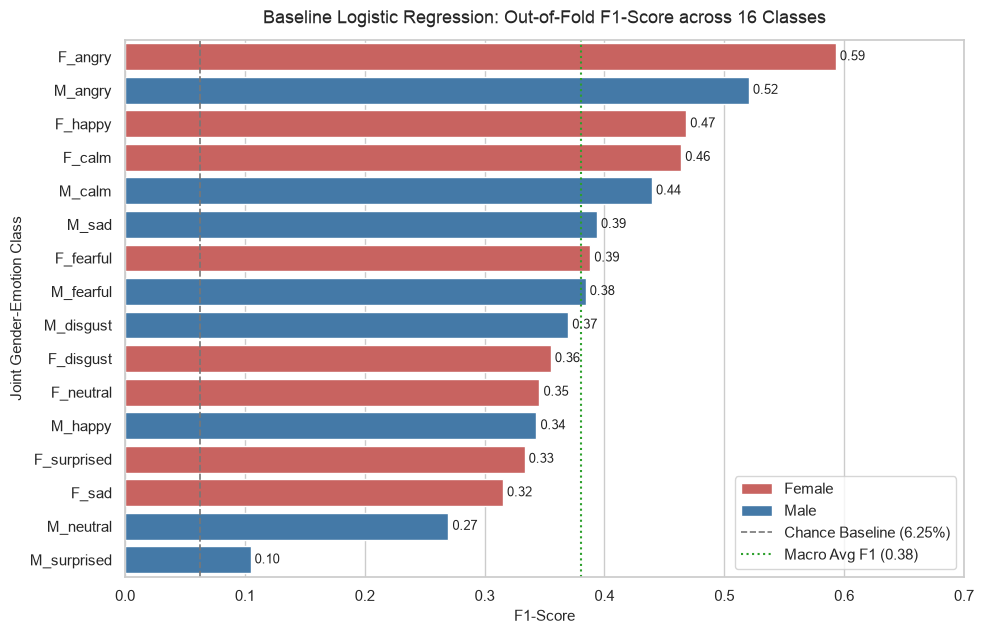

In [198]:
# Parse individual class metrics into a DataFrame
class_labels = [k for k in report_dict if k not in ("accuracy", "macro avg", "weighted avg")]
records = []
for label in class_labels:
    records.append({
        "Class": str(label),
        "f1_score": float(report_dict[label]["f1-score"]),
        "Gender": "Female" if str(label).startswith("F_") else "Male",
    })

df = pd.DataFrame(records)
df = df.sort_values(by="f1_score", ascending=False).reset_index(drop=True)

# Build plot
plt.figure(figsize=(10, 6.5))
palette = {"Female": "#d9534f", "Male": "#337ab7"}

ax = sns.barplot(
    data=df,
    x="f1_score",
    y="Class",
    hue="Gender",
    dodge=False,
    palette=palette,
)

plt.axvline(0.0625, color="#777777", linestyle="--", linewidth=1.2, label="Chance Baseline (6.25%)")
plt.axvline(macro_f1, color="#2ca02c", linestyle=":", linewidth=1.5, label=f"Macro Avg F1 ({macro_f1:.2f})")

plt.title("Baseline Logistic Regression: Out-of-Fold F1-Score across 16 Classes", fontsize=13, pad=12)
plt.xlabel("F1-Score", fontsize=11)
plt.ylabel("Joint Gender-Emotion Class", fontsize=11)
plt.xlim(0, 0.70)

# Type-safe bar labeling
for container in ax.containers:
    if isinstance(container, BarContainer):
        ax.bar_label(container, fmt="%.2f", padding=3, fontsize=9.5, color="#222222")

plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

### Key Insights from Out-of-Fold Classification Report

- Both `F_angry` (F1: 0.59, Recall: 0.61) and `M_angry` (F1: 0.52, Recall: 0.53) achieve the **highest scores**. This is likely because high vocal intensity, expanded pitch range, and high-frequency spectral energy make anger linearly separable from lower-energy states and much easier to identify.
- `M_surprised` is **an acute failure point** with **9% recall** and an **F1 score of 0.10**. The confusion matrix reveals male surprise is heavily misclassified as `M_fearful` (0.24) and `M_happy` (0.20), showing linear features *cannot disambiguate* high-pitch inflections in male voices.
- Both `F_neutral` and `M_neutral` have half the support ($n=48$ vs. $n=96$) because RAVDESS includes only "normal" intensity for neutral (no "strong" variant). This reduced training presence contributes to depressed recall across both genders (0.29 female, 0.25 male).
- `Calm` performs reliably across **both** genders (`F_calm` F1: 0.46, `M_calm` F1: 0.44), benefiting from distinct, low-variance spectral slope and low speech rates that separate it from agitated classes.

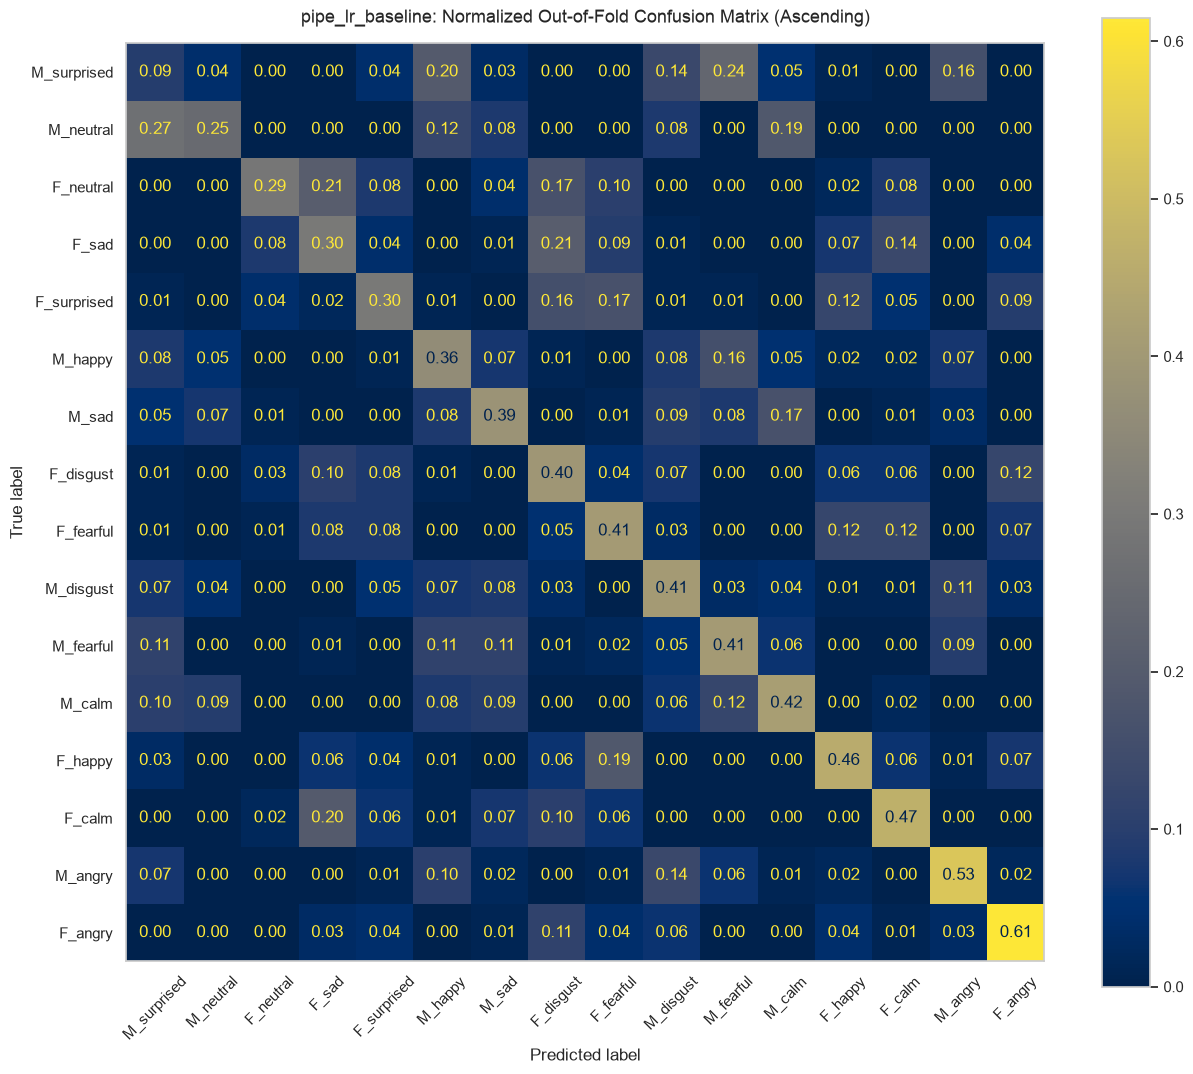

In [199]:
# Plot as Heatmap

# Compute normalized confusion matrix to extract diagonal recall values
unique_labels = np.unique(y)
cm_norm = confusion_matrix(y, y_pred_oof, labels=unique_labels, normalize="true")

# Sort ascending so the lowest recall is top-left and highest recall is bottom-right
diagonal_accuracies = cm_norm.diagonal()
sorted_indices = np.argsort(diagonal_accuracies)
sorted_labels = unique_labels[sorted_indices]

# Render confusion matrix sorted ascending along the diagonal
fig, ax = plt.subplots(figsize=(13, 11))
ax.grid(False)

ConfusionMatrixDisplay.from_predictions(
    y_true=y,
    y_pred=y_pred_oof,
    labels=sorted_labels,
    normalize="true",
    cmap="cividis",
    values_format=".2f",
    xticks_rotation=45,
    ax=ax,
    colorbar=True
)

ax.grid(False)
ax.set_title(
    "pipe_lr_baseline: Normalized Out-of-Fold Confusion Matrix (Ascending)",
    fontsize=13,
    pad=15
)

plt.tight_layout()
plt.show()

Can we identify the top wrong misclassifications?

In [200]:
top = 5

# Isolate off-diagonal errors (zero out the diagonal)
cm_sorted_norm = confusion_matrix(y, y_pred_oof, labels=sorted_labels, normalize="true")
np.fill_diagonal(cm_sorted_norm, 0.0)

# Build a tidy DataFrame of true vs predicted misclassifications
records = []
for i, true_cls in enumerate(sorted_labels):
    for j, pred_cls in enumerate(sorted_labels):
        if i != j and cm_sorted_norm[i, j] > 0:
            records.append({
                "True Label": true_cls,
                "Predicted Label": pred_cls,
                "Misclassification Rate": cm_sorted_norm[i, j]
            })

df_top_errors = (
    pd.DataFrame(records)
    .sort_values(by="Misclassification Rate", ascending=False)
    .head(top)
    .reset_index(drop=True)
)

print(df_top_errors.to_string(index=False))

 True Label Predicted Label  Misclassification Rate
  M_neutral     M_surprised                0.270833
M_surprised       M_fearful                0.239583
      F_sad       F_disgust                0.208333
  F_neutral           F_sad                0.208333
M_surprised         M_happy                0.197917


The extraction isolates the primary failure modes of the linear baseline:

1. **Arousal-Driven Confusion Dominates Valence:**
   - **`M_surprised` $\rightarrow$ `M_fearful` (23.96%)** and **`M_surprised` $\rightarrow$ `M_happy` (19.79%)**: Surprise, fear, and joy share identical acoustic arousal signatures (elevated pitch variance, high root-mean-square energy, and compressed spectral tilt). Linear decision boundaries on static MFCC statistics fail to resolve the positive/negative valence distinctions between them.
   - **`F_sad` $\rightarrow$ `F_disgust` (20.83%)** and **`F_neutral` $\rightarrow$ `F_sad` (20.83%)**: Low-arousal female recordings cluster tightly due to flat fundamental frequency ($F_0$) contours, low vocal energy, and minimal spectral change.

2. **The Neutral Support Penalty:**
   - **`M_neutral` $\rightarrow$ `M_surprised` (27.08%)**: The single highest off-diagonal error. Neutral samples possess half the representation ($n=48$ vs. $n=96$) because RAVDESS omits a "strong" intensity variant for neutral speech. The multinomial linear boundary under-fits neutral's compact space, leaking over a quarter of its samples into male surprise.

3. **Strict Intra-Gender Confinement:**
   - All top 5 misclassifications occur strictly within the same sex (`M` $\rightarrow$ `M`, `F` $\rightarrow$ `F`). Pitch register and vocal tract length cues captured by lower MFCC coefficients provide robust gender isolation, confirming errors stem entirely from emotion boundary ambiguity rather than speaker demographic leakage.

How about if we consider **just** the gender classficiation portion?

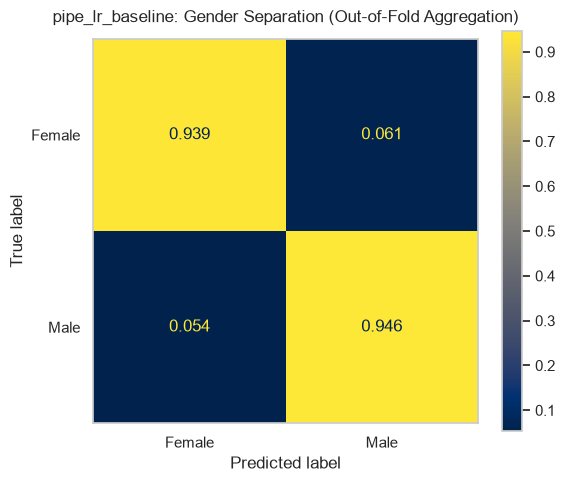

Raw Sample Counts:
             Pred Female  Pred Male
True Female          676         44
True Male             39        681

Gender Classification Metrics:
              precision    recall  f1-score   support

      Female      0.945     0.939     0.942       720
        Male      0.939     0.946     0.943       720

    accuracy                          0.942      1440
   macro avg      0.942     0.942     0.942      1440
weighted avg      0.942     0.942     0.942      1440



In [201]:
# Extract gender prefix ('F' or 'M') from the full 16-class strings
y_gender_true = np.array([label[0] for label in y])
y_gender_pred = np.array([label[0] for label in y_pred_oof])

gender_labels = ["Female", "Male"]
gender_map = {"F": "Female", "M": "Male"}

y_gender_true = pd.Series(y_gender_true).map(gender_map)
y_gender_pred = pd.Series(y_gender_pred).map(gender_map)

# 2x2 Gender Confusion Matrix (Raw Counts and Proportions)
fig, ax = plt.subplots(figsize=(6, 5))
ax.grid(False)

ConfusionMatrixDisplay.from_predictions(
    y_true=y_gender_true,
    y_pred=y_gender_pred,
    labels=gender_labels,
    normalize="true",
    cmap="cividis",
    values_format=".3f",
    ax=ax,
    colorbar=True
)

ax.grid(False)
ax.set_title("pipe_lr_baseline: Gender Separation (Out-of-Fold Aggregation)", fontsize=12, pad=12)
plt.tight_layout()
plt.show()

# Raw count breakdown
cm_gender_raw = confusion_matrix(y_gender_true, y_gender_pred, labels=gender_labels)
df_gender_counts = pd.DataFrame(
    cm_gender_raw,
    index=[f"True {g}" for g in gender_labels],
    columns=[f"Pred {g}" for g in gender_labels]
)

print("Raw Sample Counts:")
print(df_gender_counts)
print("\nGender Classification Metrics:")
print(classification_report(y_gender_true, y_gender_pred, digits=3))

### Key Takeaways

- **Gender is easy for the model:** It identifies males (~95%) and females (~94%) reliably. Pitch and vocal tract differences give the linear model a clear separation.
- **Emotion is the real problem:** When the model makes a mistake, it almost never confuses a man for a woman. It confuses emotions within the same gender (like mistaking male surprise for fear or happiness).
- **Why this happens:** Summary MFCC averages capture general voice tone, but emotions depend on changes over time - like pitch shifts, pauses, and speech cadence.


## Conclusion

* The linear baseline **achieves ~94–95% accuracy** separating male and female speakers out-of-fold. In other words, **gender identification** is already a solved problem. Cross-gender misclassifications account for only **~5.5%** of all samples, confirming that vocal tract and pitch differences are linearly separable in static MFCC feature space
* In EDA, strong acoustic separation by gender made a two-stage approach (Gender Model → Emotion Model) seem like an intuitive shortcut to simplify classification. However as mentioned in the previous point, model diagnostics revealed this provides negligible value. Adding an explicit gender stage could introduce compounding errors without solving the intra-gender bottleneck
* A limitation of converting MFCCs into static mean and standard deviation aggregates is that temporarl features like pitch inflection, cadence, and pause frequency are removed, which could help separate emotional valence. A future step could therefore be to explore different types of data (e.g. acoustic contours), our immediate next step holds the feature set constant to test whether *non-linear* estimators can better navigate the existing tabular feature space.

### Next Steps
  1. **Non-Linear Tabular Baselines:** Benchmark non-linear estimators (`SVC` with RBF kernel, tree ensembles) on the current static feature matrix to evaluate non-linear decision boundaries.
  2. **Dynamic Temporal Features:** Augment tabular features with delta/delta-delta MFCCs and prosodic contours ($F_0$) to capture cadence and inflection.
  3. **Deep Learning (CNN Architecture):** Train a 1D/2D Convolutional Neural Network directly on uncompressed time-series spectrograms (log-mel or MFCC frames) to let convolutional filters automatically learn hierarchical temporal and spectral representations without manual statistical aggregation.

In [202]:
# Final step - save models for comparision later

# Define and create the models artifact directory inside data/processed
models_dir = data_processed_path / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Fit baseline pipelines on the full dataset for persistence
pipe_dummy_baseline.fit(X, y)
pipe_lr_baseline.fit(X, y)

# Package models alongside out-of-fold predictions, labels, and cross-validation metadata
baseline_artifacts = {
    "pipe_dummy_baseline": pipe_dummy_baseline,
    "pipe_lr_baseline": pipe_lr_baseline,
    "y_pred_oof_lr": y_pred_oof,
    "cv_kfold": kfold,
    "labels": sorted_labels,
    "metadata": {
        "dataset": "RAVDESS",
        "n_samples": len(y),
        "target_type": "gender_emotion_16_class",
        "strategy": "speaker_independent_GroupKFold",
    },
}

# Save serialized artifacts
save_path = models_dir / "02_2_baseline_pipelines.joblib"
joblib.dump(baseline_artifacts, save_path)

print(f"Artifacts successfully saved to: {save_path.resolve()}")


Artifacts successfully saved to: /Users/abhisheknigam/workspace/github/my-ai/speech-emotion-router/data/processed/models/02_2_baseline_pipelines.joblib


In [203]:
# # Code to reload artifacts later

# # Resolve path to saved artifacts
# project_root = Path.cwd().resolve().parent
# models_dir = project_root / "data" / "processed" / "models"
# artifact_path = models_dir / "02_2_baseline_pipelines.joblib"

# # Load serialized baseline bundle
# baseline_artifacts = joblib.load(artifact_path)

# # Extract objects
# pipe_dummy = baseline_artifacts["pipe_dummy_baseline"]
# pipe_lr = baseline_artifacts["pipe_lr_baseline"]
# y_pred_oof_lr = baseline_artifacts["y_pred_oof_lr"]
# labels = baseline_artifacts["labels"]

# # Compute baseline benchmark metrics from saved out-of-fold predictions
# baseline_metrics = {
#     "Model": "Logistic Regression (Baseline)",
#     "Accuracy": accuracy_score(y, y_pred_oof_lr),
#     "Macro F1": f1_score(y, y_pred_oof_lr, average="macro"),
# }